(sec-5-2)=
# 5.2 The Complex Exponential Fourier Series

We already have a way to describe periodic signals with sines and cosines. Now I want to write the same description more compactly, using the complex exponentials introduced in Chapter 2. The signal itself has not changed; we are changing how we keep track of its components.

We will connect the old coefficients to the new ones before deriving them directly. Negative frequencies may look unusual at first. For a real-valued signal, the positive and negative frequency terms work together to produce the real waveform we started with.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-5-2-1)=
## 5.2.1 From Sines and Cosines to Complex Exponentials

We start from the trigonometric series [(5.1)](01_fourier_series_derivation.ipynb#eq-5-1),

$$
x(t) = a_0 + \sum_{n=1}^{\infty}\Big[a_n\cos(n\omega_0 t) + b_n\sin(n\omega_0 t)\Big],
$$

This is the same real-valued series as before. Our next step is to replace each sine and cosine with Euler's identities, then collect the terms multiplying $e^{jn\omega_0t}$ and $e^{-jn\omega_0t}$. We are rearranging a representation, so a useful check is that the reconstructed waveform stays the same.

and replace each cosine and sine by complex exponentials using equation [(2.2)](../ch02_math_toolkit/01_complex_numbers.ipynb#eq-2-2) of [Section 2.1](../ch02_math_toolkit/01_complex_numbers.ipynb):

$$
\cos\theta = \frac{e^{j\theta} + e^{-j\theta}}{2}, \qquad \sin\theta = \frac{e^{j\theta} - e^{-j\theta}}{2j}.
$$

**Step 1: substitute.** With $\theta = n\omega_0 t$, the $n$-th term becomes

$$
a_n\cos(n\omega_0 t) + b_n\sin(n\omega_0 t) = \frac{a_n}{2}\left(e^{jn\omega_0 t} + e^{-jn\omega_0 t}\right) + \frac{b_n}{2j}\left(e^{jn\omega_0 t} - e^{-jn\omega_0 t}\right).
$$

**Step 2: collect the two exponentials.** Grouping the terms that multiply $e^{jn\omega_0 t}$ and those that multiply $e^{-jn\omega_0 t}$, and using $1/j = -j$ (multiply numerator and denominator by $j$ and recall $j^2 = -1$),

$$
\begin{aligned}
a_n\cos(n\omega_0 t) + b_n\sin(n\omega_0 t) &= \left(\frac{a_n}{2} + \frac{b_n}{2j}\right)e^{jn\omega_0 t} + \left(\frac{a_n}{2} - \frac{b_n}{2j}\right)e^{-jn\omega_0 t}\\[4pt]
&= \frac{a_n - jb_n}{2}\,e^{jn\omega_0 t} + \frac{a_n + jb_n}{2}\,e^{-jn\omega_0 t}.
\end{aligned}
$$

**Step 3: name the coefficients.** Define, for $n \ge 1$,

(eq-5-12)=
\begin{equation*}
c_0 = a_0, \qquad c_n = \frac{a_n - jb_n}{2}, \qquad c_{-n} = \frac{a_n + jb_n}{2}. \tag{5.12}
\end{equation*}

Each harmonic now contributes $c_n e^{jn\omega_0 t} + c_{-n}e^{-jn\omega_0 t}$, and if we let the index run over negative integers as well, the whole series becomes a single sum,

(eq-5-13)=
\begin{equation*}
x(t) = \sum_{n=-\infty}^{\infty} c_n\, e^{jn\omega_0 t}. \tag{5.13}
\end{equation*}

This is the **complex exponential Fourier series**. Because $a_n$ and $b_n$ are real, [(5.12)](#eq-5-12) shows immediately that $c_{-n}$ is the complex conjugate of $c_n$:

(eq-5-14)=
\begin{equation*}
c_{-n} = c_n^* \qquad \text{for real } x(t). \tag{5.14}
\end{equation*}

**Step 4: one formula for every coefficient.** Inserting the integral formulas [(5.5)](01_fourier_series_derivation.ipynb#eq-5-5) and [(5.6)](01_fourier_series_derivation.ipynb#eq-5-6) for $a_n$ and $b_n$ into [(5.12)](#eq-5-12),

(eq-5-15)=
\begin{equation*}
c_n = \frac{1}{2}\cdot\frac{2}{T}\int_T x(t)\Big[\cos(n\omega_0 t) - j\sin(n\omega_0 t)\Big]dt = \frac{1}{T}\int_T x(t)\,e^{-jn\omega_0 t}\,dt, \tag{5.15}
\end{equation*}

where the bracket is $e^{-jn\omega_0 t}$ by Euler's formula. The same expression gives $c_0 = a_0$ when $n = 0$ (it reduces to the mean [(5.4)](01_fourier_series_derivation.ipynb#eq-5-4)), and for negative $n$ it gives $\frac{1}{T}\int x\,[\cos(|n|\omega_0 t) + j\sin(|n|\omega_0 t)]\,dt = (a_{|n|} + jb_{|n|})/2$, in agreement with [(5.12)](#eq-5-12). Three formulas have become one.

### Back to amplitude and phase

Going the other way is just as easy. Adding and subtracting the two lines of [(5.12)](#eq-5-12) gives $a_n = c_n + c_{-n} = 2\operatorname{Re}\{c_n\}$ and $b_n = j(c_n - c_{-n}) = -2\operatorname{Im}\{c_n\}$. More useful is the link with the amplitude–phase form [(5.11)](01_fourier_series_derivation.ipynb#eq-5-11). There we found $a_n = A_n\cos\varphi_n$ and $b_n = -A_n\sin\varphi_n$, so

(eq-5-16)=
\begin{equation*}
c_n = \frac{A_n\cos\varphi_n + jA_n\sin\varphi_n}{2} = \frac{A_n}{2}\,e^{j\varphi_n}, \qquad |c_n| = \frac{A_n}{2}, \quad \angle c_n = \varphi_n \quad (n \ge 1). \tag{5.16}
\end{equation*}

The magnitude of $c_n$ is half the amplitude of the $n$-th harmonic, and its angle is the harmonic's phase. The other half of the amplitude sits in $c_{-n}$. In phasor language, the real sinusoid $A_n\cos(n\omega_0 t + \varphi_n)$ is the sum of two counter-rotating phasors of length $A_n/2$, one spinning counterclockwise at $+n\omega_0$ and one clockwise at $-n\omega_0$, whose imaginary parts cancel at every instant.

**Example 5.2.1.** Convert the sawtooth series [(5.8)](01_fourier_series_derivation.ipynb#eq-5-8) to complex form.

The sawtooth has $a_n = 0$ and $b_n = 2(-1)^{n+1}/(n\pi)$, so by [(5.12)](#eq-5-12), for $n \ge 1$,

$$
c_n = \frac{-jb_n}{2} = \frac{-j(-1)^{n+1}}{n\pi} = \frac{j(-1)^n}{n\pi},
$$

using $-(-1)^{n+1} = (-1)^n$. For negative indices, [(5.14)](#eq-5-14) gives $c_{-n} = c_n^* = -j(-1)^n/(n\pi)$, which is the same formula evaluated at $-n$ (since $(-1)^{-n} = (-1)^n$ and $1/(-n) = -1/n$). So $c_n = j(-1)^n/(n\pi)$ for every $n \neq 0$, and $c_0 = 0$. We confirm this by evaluating [(5.15)](#eq-5-15) numerically.

In [2]:
T = 1.0
w0 = 2 * np.pi / T
M = 4000
t = -T / 2 + np.arange(M + 1) * T / M
saw = 2 * t / T
saw[[0, -1]] = 0.0                                   # midpoint of the jump


def complex_coefficients(x, t, T, n_values):
    """Complex Fourier coefficients c_n (eq. 7.15) by the trapezoidal rule over one period."""
    w0 = 2 * np.pi / T
    n_values = np.asarray(n_values)[:, None]
    return np.trapezoid(x * np.exp(-1j * n_values * w0 * t), t, axis=1) / T


n = np.arange(-4, 5)
c_num = complex_coefficients(saw, t, T, n)
c_formula = np.where(n != 0, 1j * (-1.0) ** n / (np.pi * np.where(n == 0, 1, n)), 0)
print(pd.DataFrame({"Im c_n (numeric)": c_num.imag, "Im c_n (formula)": c_formula.imag},
                   index=pd.Index(n, name="n")).round(5) + 0.0)
print(f"largest |Re c_n|: {np.abs(c_num.real).max():.1e}")

    Im c_n (numeric)  Im c_n (formula)
n                                     
-4          -0.07958          -0.07958
-3           0.10610           0.10610
-2          -0.15915          -0.15915
-1           0.31831           0.31831
 0           0.00000           0.00000
 1          -0.31831          -0.31831
 2           0.15915           0.15915
 3          -0.10610          -0.10610
 4           0.07958           0.07958
largest |Re c_n|: 1.4e-17


The real parts vanish, the imaginary parts alternate in sign and fall as $1/|n|$, and the coefficients at $\pm n$ are conjugates of each other.

(sec-5-2-2)=
## 5.2.2 Orthogonality of Complex Exponentials

The derivation above leaned on the trigonometric series. We can also derive [(5.15)](#eq-5-15) directly, and the direct route is the one that generalizes to the Fourier transform and the DFT.

For complex-valued signals on one period we use the inner product

$$
\langle x, y\rangle = \frac{1}{T}\int_T x(t)\,y^*(t)\,dt,
$$

the continuous analog of $\sum_i x_i y_i^*$ in [Section 2.2](../ch02_math_toolkit/03_signals_as_vectors.ipynb). The conjugate is essential. Without it, the "length squared" of $e^{j\omega_0 t}$ would be $\frac{1}{T}\int e^{j2\omega_0 t}dt = 0$, a nonzero vector orthogonal to itself. With it, $e^{j\omega_0 t}\,(e^{j\omega_0 t})^* = |e^{j\omega_0 t}|^2 = 1$.

Now take two harmonics $e^{jm\omega_0 t}$ and $e^{jn\omega_0 t}$ and set $k = m - n$. Their inner product is

$$
\frac{1}{T}\int_{t_0}^{t_0+T} e^{jm\omega_0 t}\,e^{-jn\omega_0 t}\,dt = \frac{1}{T}\int_{t_0}^{t_0+T} e^{jk\omega_0 t}\,dt .
$$

If $k = 0$ the integrand is 1 and the result is 1. If $k \neq 0$,

$$
\frac{1}{T}\left[\frac{e^{jk\omega_0 t}}{jk\omega_0}\right]_{t_0}^{t_0+T} = \frac{e^{jk\omega_0 t_0}}{jk\omega_0 T}\left(e^{jk\omega_0 T} - 1\right) = \frac{e^{jk\omega_0 t_0}}{j2\pi k}\left(e^{j2\pi k} - 1\right) = 0,
$$

because $e^{j2\pi k} = 1$ for every integer $k$: the phasor makes exactly $k$ full turns and returns to where it started. Hence

(eq-5-17)=
\begin{equation*}
\frac{1}{T}\int_T e^{jm\omega_0 t}\,e^{-jn\omega_0 t}\,dt = \begin{cases}1, & m = n,\\ 0, & m \neq n.\end{cases} \tag{5.17}
\end{equation*}

The harmonics $e^{jn\omega_0 t}$ are orthonormal under this inner product. To extract $c_m$, we multiply the series [(5.13)](#eq-5-13) by $e^{-jm\omega_0 t}$, integrate over a period and divide by $T$:

$$
\frac{1}{T}\int_T x(t)\,e^{-jm\omega_0 t}\,dt = \sum_{n=-\infty}^{\infty} c_n\,\underbrace{\frac{1}{T}\int_T e^{jn\omega_0 t}\,e^{-jm\omega_0 t}\,dt}_{1 \text{ if } n = m,\ 0 \text{ otherwise}} = c_m .
$$

This is [(5.15)](#eq-5-15) again, obtained without ever mentioning sines or cosines. In vector language, $c_n = \langle x, e^{jn\omega_0 t}\rangle$ is the coordinate of $x$ along the $n$-th harmonic.

### Time shifts become phase factors

One property is worth deriving right away because we use it repeatedly. Let $y(t) = x(t - t_0)$ be a delayed copy of $x$. Its coefficients are, after the substitution $u = t - t_0$ (which still integrates over one full period),

(eq-5-18)=
\begin{equation*}
d_n = \frac{1}{T}\int_T x(t - t_0)\,e^{-jn\omega_0 t}\,dt = \frac{1}{T}\int_T x(u)\,e^{-jn\omega_0 (u + t_0)}\,du = e^{-jn\omega_0 t_0}\,c_n. \tag{5.18}
\end{equation*}

A delay leaves every $|c_n|$ unchanged and subtracts $n\omega_0 t_0$ from every phase. In [Section 5.1.7](01_fourier_series_derivation.ipynb#sec-5-1-7) this took a page of trigonometry; here it is one line.

(sec-5-2-3)=
## 5.2.3 Two-Sided Line Spectra

Plotting $|c_n|$ and $\angle c_n$ against the frequency $nf_0$ for both positive and negative $n$ gives the **two-sided** magnitude and phase spectra. Negative frequencies sound strange at first. I find it easiest to think of them as the direction of rotation: $e^{jn\omega_0 t}$ is a phasor turning counterclockwise, $e^{-jn\omega_0 t}$ one turning clockwise at the same rate, and a real signal needs both so that their imaginary parts cancel.

That cancellation is exactly the conjugate symmetry [(5.14)](#eq-5-14), which we can also derive directly from [(5.15)](#eq-5-15). Conjugating $c_n$ and using $x^*(t) = x(t)$ for a real signal,

$$
c_n^* = \frac{1}{T}\int_T x^*(t)\,e^{+jn\omega_0 t}\,dt = \frac{1}{T}\int_T x(t)\,e^{-j(-n)\omega_0 t}\,dt = c_{-n}.
$$

Writing $c_n = |c_n|e^{j\angle c_n}$, the relation $c_{-n} = c_n^*$ means

$$
|c_{-n}| = |c_n|, \qquad \angle c_{-n} = -\angle c_n .
$$

**The magnitude spectrum of a real signal is even and its phase spectrum is odd.** The negative-frequency half carries no new information, which is why one-sided plots of $A_n = 2|c_n|$, as in [Section 5.1](01_fourier_series_derivation.ipynb#sec-5-1), are common in practice. Two further consequences follow from splitting [(5.15)](#eq-5-15) into $\frac{1}{T}\int x\cos(n\omega_0 t)\,dt - \frac{j}{T}\int x\sin(n\omega_0 t)\,dt$. If $x$ is real and even, the sine integral vanishes and every $c_n$ is real; if $x$ is real and odd, the cosine integral vanishes and every $c_n$ is purely imaginary. The sawtooth is odd, and indeed its coefficients in Example 5.2.1 are purely imaginary.

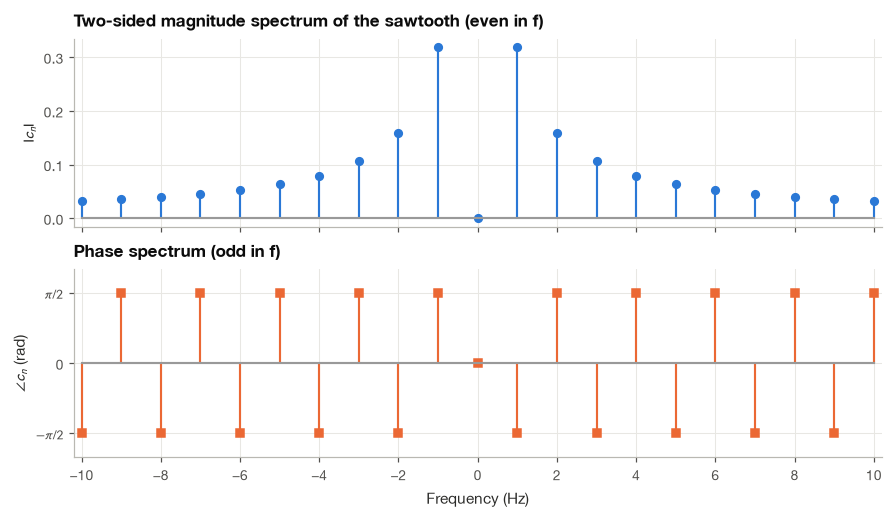

In [3]:
n = np.arange(-10, 11)
c_saw = np.where(n != 0, 1j * (-1.0) ** n / (np.pi * np.where(n == 0, 1, n)), 0)
f = n / T

fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True)
axes[0].stem(f, np.abs(c_saw), linefmt=C[0], markerfmt="o", basefmt="0.6")
axes[0].set(ylabel="$|c_n|$", title="Two-sided magnitude spectrum of the sawtooth (even in f)")
phase = np.where(np.abs(c_saw) > 1e-12, np.angle(c_saw), 0)
axes[1].stem(f, phase, linefmt=C[1], markerfmt="s", basefmt="0.6")
axes[1].set(xlabel="Frequency (Hz)", ylabel=r"$\angle c_n$ (rad)", title="Phase spectrum (odd in f)",
            yticks=[-np.pi / 2, 0, np.pi / 2], yticklabels=[r"$-\pi/2$", "0", r"$\pi/2$"], ylim=(-2.1, 2.1))
axes[1].set_xticks(np.arange(-10, 11, 2))
plt.show()

The magnitudes fall as $1/(|n|\pi)$ on both sides, and the phase alternates between $-\pi/2$ and $+\pi/2$ with exact odd symmetry about $f = 0$. When I plot a phase spectrum I set the phase to zero wherever the magnitude is zero (here at $n = 0$), because the angle of a zero coefficient is meaningless and numerical round-off would otherwise produce random values there.

```{note}
Conjugate symmetry holds only for real signals. Some biomedical signals are deliberately complex: Doppler ultrasound blood-flow systems demodulate the echo into an in-phase and a quadrature channel, and the resulting complex signal has an asymmetric spectrum in which positive frequencies mean flow toward the probe and negative frequencies flow away from it. The analytic signal of Section 23.4 is another example.
```

(sec-5-2-4)=
## 5.2.4 Parseval's Theorem and the Distribution of Power

A periodic signal has infinite energy (it never stops), so we measure it by its average **power** over one period, $P = \frac{1}{T}\int_T |x(t)|^2\,dt$, the mean-square value of Section 3.4. Parseval's theorem says that this power can be computed equally well from the Fourier coefficients.

**Step 1: write the squared magnitude as a product.** Since $|x|^2 = x\,x^*$, and the conjugate of the series [(5.13)](#eq-5-13) is $\sum_n c_n^* e^{-jn\omega_0 t}$,

$$
|x(t)|^2 = \left(\sum_{m=-\infty}^{\infty} c_m e^{jm\omega_0 t}\right)\left(\sum_{n=-\infty}^{\infty} c_n^* e^{-jn\omega_0 t}\right) = \sum_{m}\sum_{n} c_m c_n^*\, e^{j(m - n)\omega_0 t}.
$$

We used different indices $m$ and $n$ for the two sums so that every cross product appears.

**Step 2: average over a period.** Dividing by $T$, integrating term by term and applying [(5.17)](#eq-5-17), every term with $m \neq n$ vanishes and every term with $m = n$ contributes $c_n c_n^* = |c_n|^2$:

(eq-5-19)=
\begin{equation*}
P = \frac{1}{T}\int_T |x(t)|^2\,dt = \sum_{n=-\infty}^{\infty} |c_n|^2. \tag{5.19}
\end{equation*}

**Step 3: translate to the one-sided form.** For a real signal, $|c_0|^2 = a_0^2$ and, by [(5.14)](#eq-5-14) and [(5.16)](#eq-5-16), $|c_n|^2 + |c_{-n}|^2 = 2(A_n/2)^2 = A_n^2/2$. Therefore

(eq-5-20)=
\begin{equation*}
P = a_0^2 + \sum_{n=1}^{\infty}\frac{A_n^2}{2}. \tag{5.20}
\end{equation*}

The interpretation is clean. A sinusoid of amplitude $A$ has mean-square value $A^2/2$, so $A_n^2/2$ is the power of the $n$-th harmonic by itself, and $a_0^2$ is the power of the DC offset. Equation [(5.20)](#eq-5-20) says that **the total power is the sum of the powers of the harmonics**, with no cross terms. That is Pythagoras' theorem for orthogonal vectors, and it is what makes statements like "90% of the power of this waveform lies below 5 Hz" meaningful.

**Example 5.2.2.** How is the power of the square wave of Example 5.1.1 distributed among its harmonics?

The square wave takes the values $\pm 1$, so $P = 1$. Its harmonics have $A_n = 4/(n\pi)$ at odd $n$, so the $n$-th harmonic carries $A_n^2/2 = 8/(n^2\pi^2)$. The fundamental alone holds $8/\pi^2 = 81.1\%$ of the power. Parseval's theorem also gives a classical sum for free: since the powers must add up to 1,

$$
\sum_{n \text{ odd}}\frac{8}{n^2\pi^2} = 1 \quad\Longrightarrow\quad 1 + \frac{1}{9} + \frac{1}{25} + \frac{1}{49} + \cdots = \frac{\pi^2}{8}.
$$

For comparison, the triangle wave [(5.10)](01_fourier_series_derivation.ipynb#eq-5-10) has $P = \frac{1}{T}\int_{-T/2}^{T/2}(1 - 4|t|/T)^2 dt = 1/3$ (substitute $u = 1 - 4t/T$ on each half) and a fundamental of amplitude $8/\pi^2$, which carries $(8/\pi^2)^2/2 = 32/\pi^4$, a fraction $96/\pi^4 = 98.6\%$ of the total. The sawtooth [(5.8)](01_fourier_series_derivation.ipynb#eq-5-8) also has $P = 1/3$, but its fundamental, of amplitude $2/\pi$, carries only $2/\pi^2$, a fraction $6/\pi^2 = 60.8\%$. The next cell computes the cumulative fractions and asks how many harmonics each waveform needs to reach 99% of its power.

In [4]:
n = np.arange(1, 501)
harmonic_power = {
    "square":   np.where(n % 2 == 1, 8 / (n * np.pi) ** 2, 0) / 1.0,
    "triangle": np.where(n % 2 == 1, (8 / (np.pi * n) ** 2) ** 2 / 2, 0) / (1 / 3),
    "sawtooth": (2 / (n * np.pi)) ** 2 / 2 / (1 / 3),
}
rows = []
for name, frac in harmonic_power.items():
    cum = np.cumsum(frac)
    rows.append({"waveform": name, "fundamental (%)": 100 * frac[0], "first 5 harmonics (%)": 100 * cum[4],
                 "harmonics for 99%": int(np.argmax(cum >= 0.99) + 1)})
print(pd.DataFrame(rows).set_index("waveform").round(2))

          fundamental (%)  first 5 harmonics (%)  harmonics for 99%
waveform                                                           
square              81.06                  93.31                 41
triangle            98.55                  99.93                  3
sawtooth            60.79                  88.98                 61


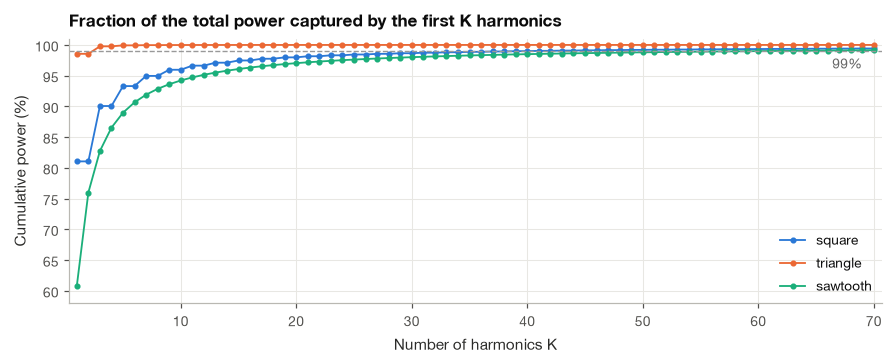

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, (name, frac) in enumerate(harmonic_power.items()):
    ax.plot(n[:70], 100 * np.cumsum(frac)[:70], "-o", color=C[k], ms=3, lw=1.2, label=name)
ax.axhline(99, color="0.6", lw=0.9, ls="--")
ax.text(69, 98.3, "99%", ha="right", va="top", fontsize=9, color="0.4")
ax.set(xlabel="Number of harmonics K", ylabel="Cumulative power (%)", ylim=(58, 101),
       title="Fraction of the total power captured by the first K harmonics")
ax.legend(loc="lower right")
plt.show()

The triangle reaches 99% with three harmonics, the square wave needs 41 and the sawtooth 61. The two waveforms with jumps spread their power over many harmonics. This is the power-domain view of the slow $1/n$ decay we noticed in [Section 5.1](01_fourier_series_derivation.ipynb#sec-5-1), and it is the reason a sharp QRS complex needs far more bandwidth than a smooth T wave.

(sec-5-2-5)=
## 5.2.5 The Rectangular Pulse Train and the Sinc Envelope

Many physiological and clinical signals are, to a first approximation, a pulse that switches on for a short time $\tau$ once every period $T$: a pacemaker stimulus, a neuromuscular stimulator, the LED drive of a pulse oximeter, the inspiratory phase of the ventilator in Section 5.1.8. The ratio $d = \tau/T$ is the **duty cycle**. Here I derive the Fourier coefficients of this pulse train, because the answer, the sinc function, appears again and again in the rest of the book.

**Example 5.2.3.** Find the complex Fourier coefficients of the pulse train that equals $A$ for $|t| < \tau/2$ and $0$ for $\tau/2 < |t| < T/2$, repeated with period $T$.

**Step 1: set up the integral.** We integrate [(5.15)](#eq-5-15) over the period $(-T/2, T/2)$. The signal is zero except on $(-\tau/2, \tau/2)$, so

$$
c_n = \frac{1}{T}\int_{-\tau/2}^{\tau/2} A\,e^{-jn\omega_0 t}\,dt .
$$

**Step 2: integrate the exponential.** For $n \neq 0$ the antiderivative of $e^{-jn\omega_0 t}$ is $e^{-jn\omega_0 t}/(-jn\omega_0)$:

$$
c_n = \frac{A}{T}\left[\frac{e^{-jn\omega_0 t}}{-jn\omega_0}\right]_{-\tau/2}^{\tau/2} = \frac{A}{T}\cdot\frac{e^{-jn\omega_0\tau/2} - e^{jn\omega_0\tau/2}}{-jn\omega_0} = \frac{A}{T}\cdot\frac{e^{jn\omega_0\tau/2} - e^{-jn\omega_0\tau/2}}{jn\omega_0}.
$$

In the last step we multiplied numerator and denominator by $-1$.

**Step 3: recognize a sine.** By [(2.2)](../ch02_math_toolkit/01_complex_numbers.ipynb#eq-2-2), $e^{j\theta} - e^{-j\theta} = 2j\sin\theta$, so the $j$'s cancel:

$$
c_n = \frac{A}{T}\cdot\frac{2\sin(n\omega_0\tau/2)}{n\omega_0} = \frac{A}{n\pi}\sin\!\left(\frac{n\pi\tau}{T}\right),
$$

where we substituted $\omega_0 = 2\pi/T$, so that $n\omega_0 T = 2\pi n$ and $n\omega_0\tau/2 = n\pi\tau/T$.

**Step 4: write it as a sinc.** Multiplying and dividing by $\tau/T$ produces a ratio of the form $\sin(\pi u)/(\pi u)$ with $u = n\tau/T$:

(eq-5-21)=
\begin{equation*}
c_n = \frac{A\tau}{T}\cdot\frac{\sin(\pi n\tau/T)}{\pi n\tau/T} = \frac{A\tau}{T}\,\operatorname{sinc}\!\left(\frac{n\tau}{T}\right) = A\,d\,\operatorname{sinc}(n d), \tag{5.21}
\end{equation*}

with the **normalized sinc function**

(eq-5-22)=
\begin{equation*}
\operatorname{sinc}(u) = \frac{\sin(\pi u)}{\pi u}, \qquad \operatorname{sinc}(0) = 1. \tag{5.22}
\end{equation*}

**Step 5: the DC term.** For $n = 0$ the formula of Step 2 divides by zero, so we go back to the integral: $c_0 = \frac{1}{T}\int_{-\tau/2}^{\tau/2}A\,dt = A\tau/T$. This agrees with [(5.21)](#eq-5-21) because $\sin(\pi u)/(\pi u) \to 1$ as $u \to 0$ (by L'Hôpital's rule, the ratio of derivatives is $\pi\cos(\pi u)/\pi \to 1$). The DC coefficient is the pulse amplitude times the duty cycle, the average value of the train. NumPy's `np.sinc` implements exactly the normalized definition [(5.22)](#eq-5-22).

Since the pulse is real and even, every $c_n$ is real, as [Section 5.2.3](#sec-5-2-3) predicts. Three features of [(5.21)](#eq-5-21) are worth reading off carefully.

- **The lines sit at multiples of $1/T$.** Only the period decides where the spectral lines are.
- **The envelope depends only on $\tau$.** Writing the frequency of the $n$-th line as $f = n/T$, we have $c_n = (A\tau/T)\operatorname{sinc}(f\tau)$: the lines sample the fixed curve $\operatorname{sinc}(f\tau)$, whose zeros are at $f = \pm 1/\tau, \pm 2/\tau, \ldots$. A harmonic falls exactly on a zero when $n$ is a multiple of $1/d$. This explains the dips at $n = 4, 8, 12$ in the ventilator spectrum of [Section 5.1.8](01_fourier_series_derivation.ipynb#sec-5-1-8), where the inspiratory pulse had $d = 1/4$.
- **Shorter pulses have broader spectra.** Halving $\tau$ doubles the width of the main lobe, $|f| < 1/\tau$, and halves the height of every line. By Parseval, the total power is $A^2 d$, and for small duty cycles about 90% of it lies inside the main lobe.

The figure shows three duty cycles at the same period $T = 1$ s.

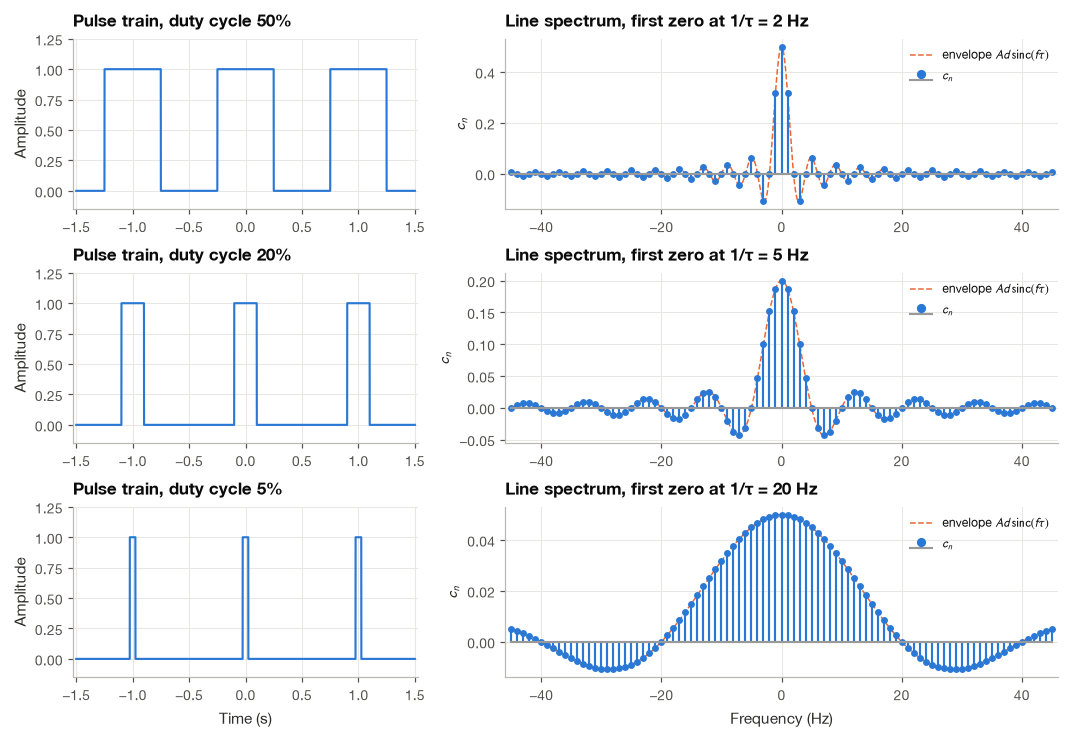

In [6]:
T, A = 1.0, 1.0
duties = (0.5, 0.2, 0.05)
t_plot = np.linspace(-1.5, 1.5, 3001)
n = np.arange(-45, 46)
f_env = np.linspace(-45, 45, 2001)

fig, axes = plt.subplots(3, 2, figsize=(9.6, 6.6), gridspec_kw={"width_ratios": [1, 1.6]})
for row, d in enumerate(duties):
    tau = d * T
    pulse = np.where(np.abs(((t_plot + T / 2) % T) - T / 2) < tau / 2, A, 0.0)
    ax = axes[row, 0]
    ax.plot(t_plot, pulse, color=C[0])
    ax.set(ylabel="Amplitude", title=f"Pulse train, duty cycle {100 * d:.0f}%", ylim=(-0.15, 1.25))
    ax = axes[row, 1]
    ax.plot(f_env, A * d * np.sinc(f_env * tau), color=C[1], lw=1, ls="--",
            label=r"envelope $A d\,\mathrm{sinc}(f\tau)$")
    ax.stem(n / T, A * d * np.sinc(n * d), linefmt=C[0], markerfmt="o", basefmt="0.6", label="$c_n$")
    ax.set(ylabel="$c_n$", title=f"Line spectrum, first zero at 1/τ = {1 / tau:.0f} Hz")
    ax.legend(loc="upper right", fontsize=8)
axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Frequency (Hz)")
for ax in axes[:, 1]:
    ax.set_xlim(-46, 46)
    for line in ax.lines:
        line.set_markersize(3.5)
plt.show()

As the duty cycle shrinks from 50% to 5%, the lines stay 1 Hz apart but the envelope stretches from a first zero at 2 Hz to one at 20 Hz, and the line heights drop from 0.5 to 0.05. In the 50% case every even harmonic falls on a zero of the envelope, which is the half-wave symmetry of [Section 5.1.6](01_fourier_series_derivation.ipynb#sec-5-1-6) seen from a different angle (a 50% pulse train minus its mean is a square wave).

I think of this figure as the first appearance of a rule that runs through the whole book: **what is short in time is wide in frequency.** A QRS complex lasting 80 to 100 ms behaves like a short pulse and fills a band tens of hertz wide, while a T wave lasting 200 ms or more needs only a few hertz. Section 8.3 turns this into the time–bandwidth trade-off of the Fourier transform.

We can also check [(5.21)](#eq-5-21) and Parseval's theorem numerically for one duty cycle.

In [7]:
d, tau = 0.2, 0.2 * T
M = 10000
t = -T / 2 + np.arange(M + 1) * T / M
pulse = np.where(np.abs(t) < tau / 2, A, 0.0)
pulse[np.isclose(np.abs(t), tau / 2)] = A / 2              # midpoint at the edges

n = np.arange(-300, 301)
c_num = complex_coefficients(pulse, t, T, n)
c_formula = A * d * np.sinc(n * d)                         # eq. (7.21)
print(f"max |c_n numeric - formula|, |n| <= 300 : {np.abs(c_num - c_formula).max():.1e}")
print(f"largest |Im c_n| (real, even signal)    : {np.abs(c_num.imag).max():.1e}")

P_time = np.trapezoid(pulse ** 2, t) / T
P_coef = np.sum(np.abs(c_formula) ** 2)
main_lobe = np.abs(n * d) < 1
print(f"power in time domain                    : {P_time:.4f}  (A^2 d = {A ** 2 * d:.4f})")
print(f"sum of |c_n|^2, |n| <= 300              : {P_coef:.4f}")
print(f"fraction inside the main lobe |f| < 1/tau: {np.sum(np.abs(c_formula[main_lobe]) ** 2) / P_time:.3f}")

max |c_n numeric - formula|, |n| <= 300 : 3.0e-06
largest |Im c_n| (real, even signal)    : 5.6e-17
power in time domain                    : 0.1999  (A^2 d = 0.2000)
sum of |c_n|^2, |n| <= 300              : 0.1997
fraction inside the main lobe |f| < 1/tau: 0.903


The numerical and analytical coefficients agree to a few parts in $10^{6}$, and the sum of $|c_n|^2$ over 601 harmonics recovers the time-domain power $A^2 d = 0.2$ to within 0.2%; the small remainder lies in the slowly decaying tail beyond $|n| = 300$. About 90% of the power sits inside the main lobe.

(sec-5-2-6)=
## 5.2.6 Computing Coefficients from One Sampled Period

In practice we never have $x(t)$ as a formula. We have samples. Suppose we record exactly one period with $N$ equally spaced samples, $x[n] = x(nT/N)$ for $n = 0, 1, \ldots, N-1$. In this subsection I switch notation: $n$ is now the sample index, as everywhere in the book for discrete signals, and $k$ is the harmonic number.

**Step 1: approximate the integral by a sum.** Replacing the integral [(5.15)](#eq-5-15) over $[0, T)$ by a Riemann sum with spacing $\Delta t = T/N$ at the sample times $t_n = nT/N$,

$$
c_k = \frac{1}{T}\int_0^T x(t)\,e^{-jk\omega_0 t}\,dt \approx \frac{1}{T}\sum_{n=0}^{N-1} x(t_n)\,e^{-jk\omega_0 t_n}\,\frac{T}{N}.
$$

**Step 2: simplify the exponent.** With $\omega_0 = 2\pi/T$ and $t_n = nT/N$, the exponent is $k\omega_0 t_n = 2\pi kn/N$, and the factors of $T$ cancel:

(eq-5-23)=
\begin{equation*}
\hat{c}_k = \frac{1}{N}\sum_{n=0}^{N-1} x[n]\,e^{-j2\pi kn/N}. \tag{5.23}
\end{equation*}

The sum in [(5.23)](#eq-5-23) is the **discrete Fourier transform** $X[k]$ of Section 10.2, so $\hat{c}_k = X[k]/N$ and `np.fft.fft(x) / N` computes all $N$ coefficients at once. Because $e^{-j2\pi kn/N}$ repeats when $k$ increases by $N$, the output index $k = N - m$ holds the negative harmonic $-m$; `np.fft.fftfreq` sorts this out.

**Step 3: understand the error.** How good is the approximation? Substitute the series [(5.13)](#eq-5-13) evaluated at the sample times, $x[n] = \sum_m c_m e^{j2\pi mn/N}$, into [(5.23)](#eq-5-23):

$$
\hat{c}_k = \sum_{m=-\infty}^{\infty} c_m\left[\frac{1}{N}\sum_{n=0}^{N-1} e^{j2\pi(m - k)n/N}\right].
$$

The bracket is a sum of $N$-th roots of unity. As shown in [Section 2.1](../ch02_math_toolkit/01_complex_numbers.ipynb), it equals 1 when $m - k$ is a multiple of $N$ and 0 otherwise. Only the indices $m = k + \ell N$ survive:

(eq-5-24)=
\begin{equation*}
\hat{c}_k = \sum_{\ell=-\infty}^{\infty} c_{k + \ell N} = c_k + c_{k+N} + c_{k-N} + c_{k+2N} + \cdots \tag{5.24}
\end{equation*}

The computed coefficient is the true one plus all the coefficients $N$ harmonics away. This is **aliasing** in the frequency domain, the same phenomenon that [Section 6.2](../ch09_sampling/index.md) studies in time. If the signal has no harmonics at or beyond $N/2$, the extra terms vanish and [(5.23)](#eq-5-23) is exact. If the coefficients decay slowly, as the $1/n$ tail of a pulse train does, the low harmonics are accurate and the error grows as $k$ approaches $N/2$.

In [8]:
d, tau = 0.2, 0.2 * T
rows = []
for N in (20, 80, 320, 1280):
    tn = np.arange(N) * T / N
    tc = ((tn + T / 2) % T) - T / 2                        # time relative to the pulse center
    x = np.where(np.abs(tc) < tau / 2, A, 0.0)
    x[np.isclose(np.abs(tc), tau / 2)] = A / 2
    c_hat = np.fft.fft(x) / N                               # eq. (7.23)
    k = np.arange(4)
    exact = A * d * np.sinc(k * d)
    alias = sum(A * d * np.sinc((k + l * N) * d) for l in range(-2000, 2001))   # eq. (7.24)
    rows.append({"N": N, "max error, k = 0..3": np.abs(c_hat[k] - exact).max(),
                 "max |c_hat - aliased sum|": np.abs(c_hat[k] - alias).max()})
print(pd.DataFrame(rows).set_index("N").to_string(float_format=lambda v: f"{v:.2e}"))

      max error, k = 0..3  max |c_hat - aliased sum|
N                                                   
20               7.58e-03                   2.27e-06
80               4.67e-04                   1.42e-07
320              2.92e-05                   8.87e-09
1280             1.82e-06                   5.54e-10


The error at the low harmonics shrinks by a factor of about 16 each time $N$ grows by a factor of 4, that is, roughly as $1/N^2$, and the last column confirms that the DFT result equals the aliased sum [(5.24)](#eq-5-24) up to the truncation of that infinite sum. The figure makes the same point across all harmonics for a coarse sampling of $N = 40$ points per period: the DFT values follow the true sinc closely at low $k$ and drift away from it as $k$ approaches $N/2 = 20$.

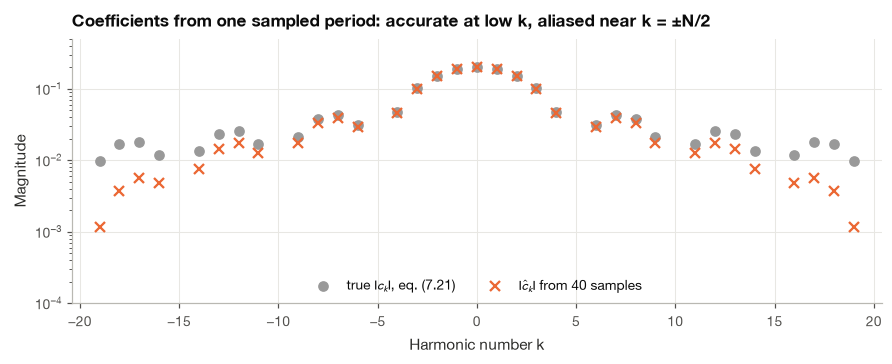

In [9]:
N = 40
tn = np.arange(N) * T / N
tc = ((tn + T / 2) % T) - T / 2
x = np.where(np.abs(tc) < tau / 2, A, 0.0)
x[np.isclose(np.abs(tc), tau / 2)] = A / 2
c_hat = np.fft.fft(x) / N
k = np.fft.fftfreq(N, 1 / N).astype(int)
order = np.argsort(k)

fig, ax = plt.subplots(figsize=(8, 3.2))
kk = np.arange(-20, 21)
ax.plot(kk, np.abs(A * d * np.sinc(kk * d)), "o", color="0.6", ms=6, label="true $|c_k|$, eq. (7.21)")
ax.plot(k[order], np.abs(c_hat[order]), "x", color=C[1], ms=6, mew=1.5, label=r"$|\hat{c}_k|$ from 40 samples")
ax.set_yscale("log")
ax.set(xlabel="Harmonic number k", ylabel="Magnitude", ylim=(1e-4, 0.5),
       title="Coefficients from one sampled period: accurate at low k, aliased near k = ±N/2")
ax.legend(loc="lower center", ncols=2)
plt.show()

Both sets of markers are missing at $k = \pm 5, \pm 10, \pm 15$. The true coefficients are zero there because the sinc envelope crosses zero, and the DFT values are exactly zero too, because every aliased index $k + 40\ell$ is again a multiple of 5 and so contributes nothing to [(5.24)](#eq-5-24). Elsewhere the aliased terms alternate in sign and partly cancel the true coefficient, which is why the DFT values fall below the sinc near $k = \pm 20$. Chapter 10 develops the DFT in full; for now, [(5.23)](#eq-5-23) is all we need to compute the Fourier series of real physiological waveforms in Section 7.4.

(sec-5-2-7)=
## 5.2.7 Application: the Spectrum of a Cardiac Pacemaker Stimulus

An implanted pacemaker stimulates the heart with brief rectangular pulses. On the surface ECG each stimulus appears as a narrow "pacing spike" just before the paced P wave or QRS complex. Clinicians rely on seeing these spikes, and yet they are notoriously hard to display: on many recordings they appear much smaller than expected, or with odd shapes. The pulse train results of this section explain why.

### Step 1: Build a model of the stimulus

I use round numbers typical of a ventricular pacemaker: a pacing rate of 60 beats/min ($T = 1$ s) and a pulse width of $\tau = 0.5$ ms. The amplitude at the pacemaker is a few volts, but on the skin it is attenuated by orders of magnitude, so I normalize the pulse height to 1. Pacemakers also balance the delivered charge: after the stimulus, the output capacitor discharges through the lead and produces a smaller, longer pulse of opposite polarity. I model this recharge phase as a rectangle of amplitude $-0.1$ and width $10\tau = 5$ ms, which removes exactly the charge the stimulus delivered. Real recharge pulses decay exponentially, so this is a simplification, but it captures the essential point.

In [10]:
T_pace, tau, tau_r, amp_r = 1.0, 0.5e-3, 5e-3, -0.1    # s, s, s, relative amplitude
fs = 200_000                                            # samples per second for the numerical check
N = int(T_pace * fs)
t = np.arange(N) / fs

mono = np.where(t < tau, 1.0, 0.0)
biphasic = mono + np.where((t >= tau) & (t < tau + tau_r), amp_r, 0.0)
for x, edges in ((mono, [(0, 0.5), (tau, 0.5)]),
                 (biphasic, [(0, 0.5), (tau, 0.5 * (1 + amp_r)), (tau + tau_r, 0.5 * amp_r)])):
    for te, val in edges:
        x[int(round(te * fs))] = val                    # midpoint values at the jumps
print(f"net charge per period (pulse area): monophasic {mono.sum() / fs * 1e3:.3f} ms, "
      f"biphasic {biphasic.sum() / fs * 1e3:.1e} ms")

net charge per period (pulse area): monophasic 0.500 ms, biphasic -7.1e-17 ms


### Step 2: Write down the coefficients in closed form

Each phase is a rectangular pulse, so [(5.21)](#eq-5-21) gives its coefficients when the pulse is centered at $t = 0$, and the delay rule [(5.18)](#eq-5-18) shifts it to where it actually occurs. The stimulus is centered at $\tau/2$ and the recharge pulse at $\tau + \tau_r/2$:

$$
c_n = \frac{\tau}{T}\operatorname{sinc}\!\left(\frac{n\tau}{T}\right)e^{-jn\omega_0\tau/2} \;+\; a_r\frac{\tau_r}{T}\operatorname{sinc}\!\left(\frac{n\tau_r}{T}\right)e^{-jn\omega_0(\tau + \tau_r/2)},
$$

with $a_r = -0.1$. At $n = 0$ both sincs equal 1 and the two terms are $\tau/T$ and $a_r\tau_r/T = -\tau/T$, so $c_0 = 0$: a charge-balanced stimulus has no DC component. That is the purpose of the recharge phase, since a net direct current through the electrode–tissue interface would cause electrolysis and tissue damage.

In [11]:
def pacing_coefficients(n, biphasic=True):
    """Fourier coefficients of the pacing pulse train from eq. (7.21) and the delay rule (7.18)."""
    w0 = 2 * np.pi / T_pace
    c = tau / T_pace * np.sinc(n * tau / T_pace) * np.exp(-1j * n * w0 * tau / 2)
    if biphasic:
        c = c + amp_r * tau_r / T_pace * np.sinc(n * tau_r / T_pace) * np.exp(-1j * n * w0 * (tau + tau_r / 2))
    return c

### Step 3: Check the formula against the DFT of the sampled pulse train

In [12]:
k = np.arange(0, 3001)
for name, x, bi in (("monophasic", mono, False), ("biphasic", biphasic, True)):
    c_hat = np.fft.fft(x)[: k.size] / N                  # eq. (7.23), harmonics 0..3000
    err = np.abs(c_hat - pacing_coefficients(k, bi)).max()
    print(f"{name:10s}: c_0 = {c_hat[0].real:+.2e}, max |DFT - formula| for k <= 3000: {err:.1e}")

monophasic: c_0 = +5.00e-04, max |DFT - formula| for k <= 3000: 7.9e-08
biphasic  : c_0 = -2.80e-20, max |DFT - formula| for k <= 3000: 8.3e-08


The closed form and the DFT of 200,000 samples agree to within about $8\times10^{-8}$, less than 0.02% of the largest coefficient $\tau/T = 5\times10^{-4}$. The small residual is the coefficient aliasing [(5.24)](#eq-5-24) of the previous subsection.

### Step 4: Compare the spectrum with the ECG bandwidth

A diagnostic ECG amplifier passes roughly 0.05 to 150 Hz and a bedside monitor often only 0.5 to 40 Hz. With a fundamental of 1 Hz, those bands contain only the first 150 or 40 harmonics of the pacing train, while the sinc envelope of a 0.5 ms pulse does not reach its first zero until $1/\tau = 2000$ Hz.

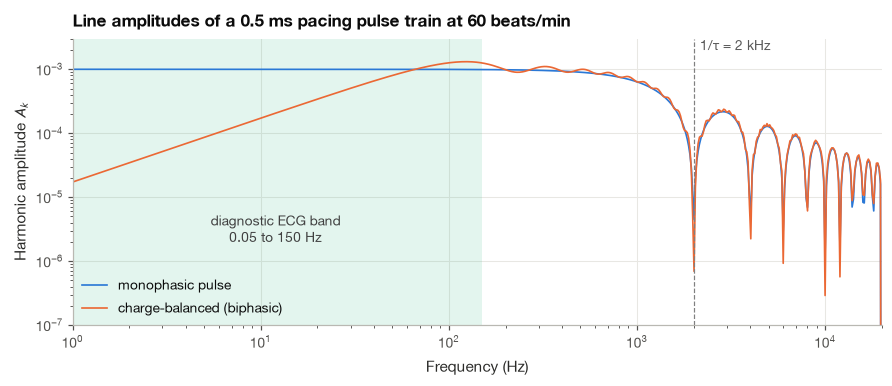

In [13]:
k_plot = np.unique(np.round(np.logspace(0, np.log10(20000), 600)).astype(int))
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.axvspan(0.05, 150, color=C[2], alpha=0.12, lw=0)
ax.text(12, 2e-6, "diagnostic ECG band\n0.05 to 150 Hz", ha="center", fontsize=9, color="0.25")
for name, bi, col in (("monophasic pulse", False, C[0]), ("charge-balanced (biphasic)", True, C[1])):
    mag = 2 * np.abs(pacing_coefficients(k_plot, bi))   # one-sided amplitude A_k = 2|c_k|
    ax.loglog(k_plot / T_pace, mag, color=col, lw=1.1, label=name)
ax.axvline(1 / tau, color="0.5", lw=0.8, ls="--")
ax.text(1 / tau * 1.08, 2e-3, "1/τ = 2 kHz", fontsize=9, color="0.35")
ax.set(xlabel="Frequency (Hz)", ylabel="Harmonic amplitude $A_k$", ylim=(1e-7, 3e-3), xlim=(1, 2e4),
       title="Line amplitudes of a 0.5 ms pacing pulse train at 60 beats/min")
ax.legend(loc="lower left")
plt.show()

With a line every hertz there are 20,000 lines up to 20 kHz, so I draw a continuous curve through their tops and use log–log axes to make both ends of the spectrum visible. The monophasic pulse has a flat spectrum all the way to about 1 kHz, then rolls off into the sinc lobes. The charge-balanced version has the same high-frequency content but much less at low frequencies, where the stimulus and recharge phases cancel; its line amplitudes grow in proportion to frequency up to about 100 Hz. Either way, the ECG band is a small corner of the spectrum.

### Step 5: Quantify how much of the spike survives

Parseval's theorem [(5.19)](#eq-5-19) lets us state this as a fraction of power, and truncating the series at 150 harmonics shows what the spike looks like after an ideal 150 Hz band limit.

In [14]:
k_all = np.arange(-20000, 20001)
t_zoom = np.linspace(-0.01, 0.02, 1201)
rows, shapes = [], {}
for name, bi in (("monophasic", False), ("biphasic", True)):
    c = pacing_coefficients(k_all, bi)
    P = (tau + bi * amp_r ** 2 * tau_r) / T_pace       # exact power, mean of x^2 over a period
    row = {"pulse": name}
    for B in (40, 150, 1000):
        row[f"<{B} Hz (%)"] = 100 * np.sum(np.abs(c[np.abs(k_all) <= B]) ** 2) / P
    kb = np.arange(-150, 151)
    x150 = np.real(np.exp(2j * np.pi * np.outer(t_zoom, kb) / T_pace) @ pacing_coefficients(kb, bi))
    shapes[name] = x150
    row["peak, 150 Hz limit"] = x150.max()
    rows.append(row)
print(pd.DataFrame(rows).set_index("pulse").round(3))

            <40 Hz (%)  <150 Hz (%)  <1000 Hz (%)  peak, 150 Hz limit
pulse                                                                
monophasic       4.048       14.957        77.390                0.15
biphasic         0.566       14.027        77.211                0.12


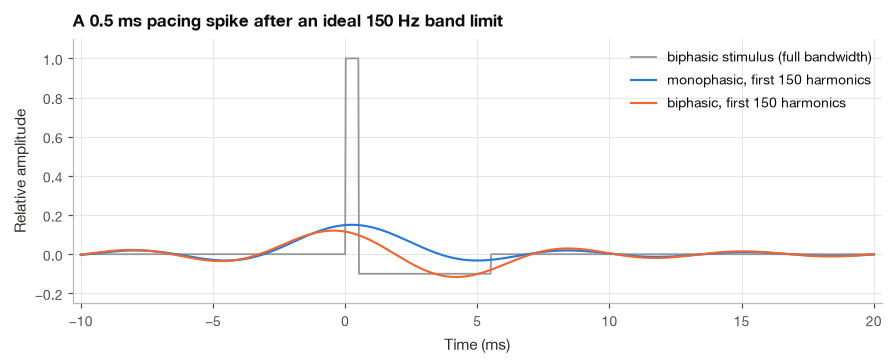

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ideal = np.where((t_zoom >= 0) & (t_zoom < tau), 1.0, 0.0) + \
    np.where((t_zoom >= tau) & (t_zoom < tau + tau_r), amp_r, 0.0)
ax.plot(1e3 * t_zoom, ideal, color="0.6", lw=1.2, label="biphasic stimulus (full bandwidth)")
ax.plot(1e3 * t_zoom, shapes["monophasic"], color=C[0], label="monophasic, first 150 harmonics")
ax.plot(1e3 * t_zoom, shapes["biphasic"], color=C[1], label="biphasic, first 150 harmonics")
ax.set(xlabel="Time (ms)", ylabel="Relative amplitude", ylim=(-0.25, 1.1),
       title="A 0.5 ms pacing spike after an ideal 150 Hz band limit")
ax.legend(loc="upper right")
plt.show()

Only about 15% of the stimulus power lies below 150 Hz and about 4% below 40 Hz, and the charge-balanced pulse has even less at the low end (about 0.6% below 40 Hz). After the 150 Hz band limit, the 1-unit spike becomes a rounded bump about 0.15 units high and several milliseconds wide, and the biphasic version turns into a small up–down deflection between about $+0.12$ and $-0.11$. The spike has not disappeared, but it is shrunk and smeared, and at monitoring bandwidths it can vanish into the ECG.

```{important}
This is why ECG equipment cannot rely on the ordinary diagnostic signal path to show pacemaker activity. Many ECG front ends detect pacing pulses in a separate channel sampled at several kilohertz, before the band-limiting filters, and then mark the detected pulses on the display. When you see a crisp vertical pacing spike on a monitor, it is often a drawn marker rather than the filtered signal itself.
```

## Summary

The complex exponential Fourier series writes a periodic signal as $x(t) = \sum_n c_n e^{jn\omega_0 t}$ with the single coefficient formula $c_n = \frac{1}{T}\int_T x(t)e^{-jn\omega_0 t}dt$. We derived it from the trigonometric series with Euler's formula, which gives $c_n = (a_n - jb_n)/2$, $|c_n| = A_n/2$ and $\angle c_n = \varphi_n$, and again from the orthonormality of the harmonics $e^{jn\omega_0 t}$. For real signals $c_{-n} = c_n^*$, so the two-sided magnitude spectrum is even and the phase spectrum is odd. Parseval's theorem $P = \sum_n|c_n|^2$ shows that the power of a periodic signal is the sum of the powers of its harmonics; signals with jumps spread their power over many harmonics. A rectangular pulse train has coefficients $A d\,\operatorname{sinc}(nd)$, with lines spaced by $1/T$ under an envelope whose width is set by $1/\tau$, a first statement of the time–bandwidth trade-off. Finally, the coefficients can be computed from one sampled period as $\frac{1}{N}\sum_n x[n]e^{-j2\pi kn/N}$, which is the DFT divided by $N$ and is exact up to aliasing of the coefficients.

[Section 5.3](03_convergence_gibbs.ipynb) asks what happens when the series is truncated near a jump, as in the band-limited pacing spike above. Section 7.4 applies the DFT formula [(5.23)](#eq-5-23) to real ECG and PPG cycles, and Chapter 8 lets the period grow without bound to obtain the Fourier transform.

## Exercises

1. Starting from [(5.15)](#eq-5-15), show directly (without the trigonometric series) that $a_n = c_n + c_{-n}$ and $b_n = j(c_n - c_{-n})$ for a real signal.
2. Find the complex Fourier coefficients of $x(t) = \cos^3(\omega_0 t)$ by expanding with Euler's formula, without evaluating any integral. Check your answer with `complex_coefficients`, and verify Parseval's theorem.
3. A pulse train of duty cycle $d$ is shifted so that each pulse starts at $t = 0$ instead of being centered there. Use [(5.18)](#eq-5-18) to write its coefficients and show that the magnitude spectrum is unchanged. For which $d$ is the shifted train half-wave symmetric after its mean is removed?
4. Using [(5.21)](#eq-5-21) and Parseval's theorem, show that $\sum_{n=-\infty}^{\infty}\operatorname{sinc}^2(nd) = 1/d$ for $0 < d \le 1$. Check the identity numerically for $d = 0.3$.
5. Repeat the computation of [Section 5.2.6](#sec-5-2-6) for the triangle wave [(5.10)](01_fourier_series_derivation.ipynb#eq-5-10) instead of the pulse train. How large must $N$ be for the first five coefficients to be accurate to $10^{-6}$? Explain the difference from the pulse train using [(5.24)](#eq-5-24) and the decay rate of the coefficients.
6. Replace the rectangular recharge phase of the pacemaker model by an exponential, $a\,e^{-(t - \tau)/\tau_r}$ for $t > \tau$, with $a$ chosen for charge balance and $\tau_r = 3$ ms. Compute its coefficients numerically with [(5.23)](#eq-5-23), plot the line spectrum, and recompute the fraction of power below 40 Hz and 150 Hz.

## Further Reading

{cite:t}`oppenheim1997` (Chapter 3) develops the exponential Fourier series and its properties in detail, including the pulse train, and {cite:t}`lathi2018` (Chapter 6) gives many further worked examples of line spectra and Parseval's theorem. {cite:t}`bracewell2000` is the classic reference for the sinc function and its pictorial use. For the measurement problems that pacing spikes cause in ECG recording, and for ECG amplifier bandwidths in general, see {cite:t}`webster2010`.